# Encoding Geographical Risk from a Global Sanction Datasets

## A Structured Open Source Intelligence Tool to support Regulatory and AML/CFT Compliance
---

**Author**: Francesco Silvano, MEng in Engineering Management  

**Instructors**: Prof. Marco Maggini, Prof. Federico Becattini

**Course**: Business Intelligence, University of Siena 

**Publication Date**: June 2026

---

## Introduction & Context

Business analysts need powerful tools to overcome the challenges of today's complex data collection and analysis. The main issue is that cross-referencing datasets is highly time-consuming and costly. 

Open-source options do exist, but they tend to lag behind in terms of data quality, retrieval speed and user-friendliness. This is particularly true in the field of sanctions compliance, where the stakes are high and the data is complex.

Businesses engage with dozens of counterparties daily — suppliers, clients, intermediaries, investors. The information asymmetry is structural: a complete understanding of who you are dealing with it’s almost impossible, but the gap between what you know and what you need to know has measurable consequences.

Here, a sanctions intelligence system is proposed to help analysts navigate the complex web of sanctions data, providing actionable insights into the relationships between entities and the potential risks associated with them. The system is built on top of open source datasets that maps entity relationships, attempts to detect evasion patterns, and exposes findings through an interactive dashboard.

- and ... The scope is to identify potential patterns and factors that influence ..., which can inform better ...  practices and policy decisions in the .... industry.

- The dataset includes a comprehensive collection of ..
- The analysis focuses on identifying patterns of ...

---

## Methodology

The datasets employed in this analysis are publicly sourced from [OpenSanctions](https://opensanctions.org), a public repository of global sanction data. The datasets include information on sanctioned entities - people, organizations and vessels - as well as complementary data on politically exposed persons (PEPs) and financial securities. 

The built pipeline ingests and combines multiple datasets, clean data ensuring that datasets are in a usable format and that any inconsistencies or missing values are addressed; an enrichment layer includes sanctioned maritime vessels and financial securities through complementary data joins - providing an holistic view of the activities carried out by sanctioned entities.

In Part I a throghout exploration of the datasets is perfomed to understand the distribution and quality of data across different types of entities and countries; in Part II we build the analytical layers: the data mining layer attempts to identify frequent patterns and associations in the data using an A-Priori algorithm for frequent itemsets and Jaccard Similarity for entity deduplication and collaborative filtering, while a recommendation system based on UV-decomposition via Stochastic Gradient Descent (SGD) suggests potential connections between entities based on their attributes and relationships; In Part III, a simple machine learning model is proposed to predict risk levels based on geographical and entity-specific features, providing a probabilistic assessment of potential sanctions evasion. 

### A few assumptions to be aware of

The analysis is based on the assumption that the datasets used are comprehensive and accurate representations of the entities and relationships involved in sanctions. While OpenSanctions is an authorative source, and their updates are frequent, the available data may not capture all information in real time, and there may be gaps or inaccuracies.

Moreover, OpenSactions distributes data in the _FollowTheMoney (FTM)_ format, which is a specific structure for representing entities and their relationships. This format is in JSON, which requires significant preprocessing to be transformed into a structured format suitable for analysis. For the purpose of this analysis, a simpler version of the data in CSV format is used, which may not capture all the nuances and details present in the original JSON data.

The cut-off date for the data is set to 10/06/2026, and any events or changes that occurred after this date are not included in the analysis. This means that the findings may not reflect the most current state of sanctions and related activities.

## Technology Dependency

```
0 Setup
└── 1 Ingest
    └── 2 Features
        ├── 3 Jaccard Dedup  ──────────────────────────────┐
        │   └── [deduped]                                  │
        │       ├── 4 Frequent Itemsets                    │
        │       │   └── [rules, fi_flags]                  │
        │       ├── 5 Network                              │
        │       │   └── [G, centrality, communities]       │
        │       │       ├── 6 Recommendation System        │
        │       │       │   └── [risk_score via UV]        │
        │       │       └── 7 ML Classifier ───────────────┘
        │       │           └── [risk_score]
        │       └── 8 Evasion Detection
        │           └── [evasion_score, evasion_flag]
        └── 9 Quarto Dashboard for Visualization
```

## Possible applications
---

| # | Application | Description | Example |
| --- | --- | --- | --- |
| 1 | Policy Evaluation and Public Accountability | Lorem Ipsum | Lorem Ipsum |
| 2 | Predictive Analytics for Project Management | Lorem Ipsum | Lorem Ipsum |
| 3 | Risk Management | Lorem Ipsum | Lorem Ipsum |
| 4 | Resource Allocation and Prioritisation | Lorem Ipsum | Lorem Ipsum |
| 5 | Decision Support Systems | Creating decision support tools for KYC/KYB functions in corporations and policymakers that leverage data insights to optimise project planning, execution, and monitoring processes. | Lorem Ipsum |
| 6 | Predictive Modeling | Lorem Ipsum | Train supervised models to forecast risk level . Predict final risk classification from partial project data (e.g., at 30%, 60% completion); Quantify feature importance to identify which variables drive risk most reliably; produce probability estimates per class, not just point predictions, to support decision thresholds |

---

## Libraries and Imports

In [ ]:
# Data
import pandas as pd
import numpy as np
from scipy import stats

# Other tools
import json, re, hashlib, itertools, collections, math, warnings
from pathlib import Path

# Similarity
from datasketch import MinHash, MinHashLSH        # MinHash-based Jaccard LSH

# A-Priori Algorithm
from mlxtend.frequent_patterns import apriori, association_rules 
from mlxtend.preprocessing import TransactionEncoder

# LDA, QDA use module: scikit learn
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.inspection import DecisionBoundaryDisplay

# Vizualization
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

# Machine Learning
# from sklearn.linear_model import SGDClassifier
# from sklearn.preprocessing import StandardScaler
# from sklearn.pipeline import Pipeline
# from sklearn.metrics import (classification_report, roc_auc_score,
#                              average_precision_score)
# from sklearn.model_selection import StratifiedKFold
# from scipy.sparse import lil_matrix, csr_matrix

### Collection and Update Process

The dataset _coverage_ [^1] - so when it was started and how frequently it is updated - is "on the hour", every 6 hours, and reflect the latest submissions and updates from the original sources. The dataset is updated automatically, however for the purpose of this project, a static snapshot of the data was taken on 10/06/2026 - the date on which a final analysis has been run - to ensure consistency across the analysis and avoid potential issues with data changes during the project timeline.   


[^1]: We use the term coverage inside dataset metadata to describe when a dataset is added to the database (dataset.coverage.start), and how often it is updated. While most data sources are updated automatically in specific intervals (the update frequency, dataset.coverage.frequency), this there are some exceptions. This includes datasets where the original publisher has stopped releasing updates of the data, and datasets where we cannot fully automate the retrieval process (e.g. because of a firewall preventing automated access, or because the data is released in an unstructured form that requires manual cleaning). Some datasets are simply static documents: lists mandated by a law, or reports that are only published once.

### Data Quality

The data in this collection originates from a variety of sources and therefore varies in terms of detail and precision (e.g., many listings of political office holdersdo not include their exact birth dates or full given names).

This represents a significant challenge for data quality, as it can lead to difficulties in entity resolution and risk assessment. For instance, the lack of precise identifiers may result in false positives or negatives when screening for sanctioned entities, which can have serious implications for compliance efforts. 

- To mitigate these issues, the dataset includes metadata on the source and confidence level of each entry, allowing users to assess the reliability of the information and make informed decisions based on the available data.

### Limitations

| Limitation Type | Description | Dataset | 
| --- | --- | --- |
| Data Completeness | Sanctions Sanctions designation wouldn’t be in the PEPs collection because those sources don’t contain the designations texts. The correct thing to do would be to filter the default dataset for entities with both the topics “sanction” and “role.pep”. This would be a more accurate way to identify PEPs that are also sanctioned, but it would also significantly reduce the number of entities in the dataset, which may limit the analysis. However, the topics are not included in the targets.simple.csv, they are only in the JSON. | Consolidated Sanctions, PEPs |

### License and Terms of Use (DA SCRIVERE)

---

## Part I: Data Exploration and Preprocessing
---

### Describing the main datasets

#### Consolidated Sanctions

The _"Consolidated Sanctions"_ dataset is a distribution listing all the sanctioned entities designated by different countries and  international organisations. This can include military, trade and travel restrictions.

This collection combines all designated entities from the various sanctions lists included in OpenSanctions. It represents the broadest set of sanctioned people, companies and other assets that is designated globally.

In [ ]:
# Load the data for Consolidated Sanctions dataset
df_consolidated = pd.read_csv('data/raw/consolidatedsanctions/targets.simple-1.csv', low_memory=False).drop(columns=['phones','emails']) # phones and emails are dropped for simplicity
df_consolidated['countries'] = df_consolidated['countries'].str.upper()

#### Politically Exposed Persons (PEPs) dataset

The _"Politically Exposed Persons (PEPs)"_ dataset is a collection of individuals who are or have been entrusted with prominent public roles.

This dataset is important for financial institutions and other entities that are required to conduct enhanced due diligence on PEPs to mitigate risks of corruption and money laundering. It includes information on the individual's name, position, country of origin, and any associated risks.

In [ ]:
# Load the data for the PEPs dataset
df_peps = pd.read_csv('data/raw/peps/targets.simple-1.csv', low_memory=False) # low_memory=False to avoid dtype warnings
df_peps['countries'] = df_peps['countries'].str.upper()
df_peps

In [ ]:
df_peps.head()
n_peps = df_peps['id'].nunique() # check number of unique entities in PEPs dataset
n_duplicates = df_peps['name'].duplicated().sum() # check for duplicates in PEPs dataset

print(f"Number of unique entities in PEPs dataset: {n_peps}")
print(f"Number of duplicates in PEPs dataset: {n_duplicates}")

# create a new dataframe with n_duplicates
# df_duplicates = df_peps[df_peps['name'].duplicated(keep=False)].sort_values('name')

#### Cleaning the main datasets

Although no extensive cleaning process was required for the datasets, as they were already in a structured format and did not contain significant missing values or inconsistencies, some preprocessing steps were necessary to ensure the data was in a usable format for analysis.

The PEPs dataset, in particular, required a deduplication process due to the presence of duplicates across different sources.

The deduplication process was implemented by simply keeping the occurrence with the most complete information, i.e. the row with the least number of missing values across all columns. This approach ensured that we retained the most informative record for each unique entity while eliminating redundant entries that could jeopardize the accuracy of our analysis. 

In [ ]:
# Create a new column 'non_null_count' that counts the number of non-null values in each row
df_peps['non_null_count'] = df_peps.count(axis=1) # .coun(axis=1) counts non-null values across columns for each row

# For each duplicate name, keep the row with the highest 'non_null_count'
df_peps_def = df_peps.sort_values('non_null_count', ascending=False).drop_duplicates(subset='name', keep='first').drop(columns=['non_null_count'])
# Check the number of unique entities and duplicates after deduplication
print(f"Number of unique entities: {df_peps_def['name'].nunique()}")
print(f"Number of duplicates removed: {df_peps.shape[0] - df_peps_def.shape[0]}")

In [ ]:
df_peps_def

In [ ]:
df_sanctioned_people = df_consolidated[df_consolidated['schema'] == 'Person']
df_sanctioned_people

The `df_sanctioned_people` dataframe contains only the entities from the Consolidated Sanctions dataset that are classified as 'Person' under the 'schema' column. These are all the individuals that have been designated as sanctioned entities by different countries and international organisations.

#### Merge datasets and create a unified view of the data (DA RISCRIVERE)
---

We have two datasets now: `df_sanctioned_people` which contains all the individuals from the Consolidated Sanctions dataset, and `df_peps_def` which contains the deduplicated list of Politically Exposed Persons (PEPs) from the PEPs dataset.

Both datasets use the same unique identifier for entities, which is the `id` column. Merging the datasets on this shared identifier yields an unified view that facilitates comprehensive analysis of interconnections between sanctioned entities and politically exposed persons (PEPs). 

We want to merge the two datasets in a way to obtain all the PEPs that are also sanctioned entities. Since both datasets use the same unique identifier for entities, which is the `id` column, we can merge them on this shared identifier to get a unified view that facilitates comprehensive analysis of interconnections between sanctioned entities and politically exposed persons (PEPs).

In this way we have obtained a consolidated dataset of PEPs that are also sanctioned entities, which can be used for further analysis to identify patterns and relationships between these entities.

#### Distribution of sanctioned individuals by country

##### Sanctioned individuals that are not PEPs

In [ ]:
df_sanctioned_people_nopeps = df_sanctioned_people[~df_sanctioned_people['id'].isin(df_peps_def['id'])]
df_sanctioned_people_nopeps

In [ ]:
country_counts = df_sanctioned_people_nopeps['countries'].value_counts()

country_percentage = country_counts / country_counts.sum()

main_countries = country_counts[country_percentage >= 0.02]
other_countries = country_counts[country_percentage < 0.02].sum()

plot_data = main_countries.copy()
if other_countries > 0:
    plot_data['Others'] = other_countries

fig = plt.figure(figsize=(10, 6))
plot_data.plot(
    kind='pie',
    autopct='%1.1f%%', # autopct to show percentage on the pie chart
    startangle=90,
    pctdistance=0.8
)

plt.title('Distribution of sanctioned individuals by country')
plt.axis('equal')
plt.tight_layout()
plt.legend()
plt.show()

##### Sanctioned individuals that are also PEPs

Analyzing the distribution of the sanctioned PEPs by country allows us to understand how many politically exposed persons are sanctioned in each country, and to identify any patterns or trends in the distribution of sanctions across different countries. This can provide insights into the geopolitical and economic factors that may influence sanctions designation, and can inform risk assessment and compliance efforts for entities operating in those countries.

In [ ]:
df_sanctioned_people_peps = pd.merge(df_sanctioned_people, df_peps_def, on='id', how='inner', suffixes=('_consolidated', '_peps'))
df_sanctioned_people_peps

The resulting dataset is typically named "The Russian Government" by the analysts for the presence of many high-profile Russian politicians and oligarchs who are both sanctioned and politically exposed. This subset can be analyzed further to understand the overlap between the two datasets and to identify any unique characteristics of these entities.

In [ ]:
country_counts = df_sanctioned_people_peps['countries_peps'].value_counts()

country_percentage = country_counts / country_counts.sum()

main_countries = country_counts[country_percentage >= 0.02]
other_countries = country_counts[country_percentage < 0.02].sum()

plot_data = main_countries.copy()
if other_countries > 0:
    plot_data['Others'] = other_countries

fig = plt.figure(figsize=(10, 6))
plot_data.plot(
    kind='pie',
    autopct='%1.1f%%', # autopct to show percentage on the pie chart
    startangle=90,
    pctdistance=0.8
)

plt.title('Distribution of sanctioned PEPs by country')
plt.axis('equal')
plt.tight_layout()
plt.legend()
plt.show()

### Describing the Enrichment Layers

#### Sanctioned Maritime Vessels

In [ ]:
df_maritime = pd.read_csv('data/raw/maritime/maritime.csv', low_memory=False) # low_memory=False to avoid dtype warnings
df_maritime['countries'] = df_maritime['countries'].str.upper()
df_maritime['flag'] = df_maritime['flag'].str.upper()

#### Sanctioned Securities

In [ ]:
df_securities = pd.read_csv('data/raw/securities/securities.csv', low_memory=False)
df_securities['countries'] = df_securities['countries'].str.upper()

#### Distribution of sanctioned non-individual entities by country

##### Sanctioned vessels

In [62]:
df_maritime

,type,caption,imo,risk,countries,flag,mmsi,id,url,datasets,aliases
0,VESSEL,BOUDREAUX TIDE,IMO9427366,mare.detained;reg.warn,VU,VU,NaN,abuja-mou-det-0059aae88f59011c58de8f5bc1d7d986...,https://www.opensanctions.org/entities/abuja-m...,abuja_mou_detention,NaN
1,VESSEL,MT UNGIESHI,IMO9261841,mare.detained;reg.warn,PA,PA,NaN,abuja-mou-det-008a22106d7ad7f4d4e184b01bbd61f4...,https://www.opensanctions.org/entities/abuja-m...,abuja_mou_detention,NaN
2,VESSEL,HACI SEMSETTIN DUNDAR,IMO9045699,mare.detained;reg.warn,PA,PA,NaN,abuja-mou-det-088511901b0456a70ec6288207972686...,https://www.opensanctions.org/entities/abuja-m...,abuja_mou_detention,NaN
3,VESSEL,SIRAYA WISDOM,IMO9403841,mare.detained,PA,PA,NaN,abuja-mou-det-094320324411c3158780fc172d24b2cb...,https://www.opensanctions.org/entities/abuja-m...,abuja_mou_detention,NaN
4,VESSEL,BBC OLYMPUS,IMO9508457,mare.detained,AG,AG,NaN,abuja-mou-det-0a5094c74d3f88de2254405dfe3d8aa1...,https://www.opensanctions.org/entities/abuja-m...,abuja_mou_detention,NaN
...,...,...,...,...,...,...,...,...,...,...,...
17314,VESSEL,DONG FENG 6,IMO9008201,sanction,NaN,NaN,NaN,un-1718-f63806bb0ad4c75d3347907c5684a669fc4f636e,https://www.opensanctions.org/entities/un-1718...,un_1718_vessels,NaN
17315,VESSEL,Hangton No. 112,NaN,sanction,NaN,NaN,NaN,us-cbpfl-0b3f7392a785c689f86ea31cc4b21cef1eb2c00b,https://www.opensanctions.org/entities/us-cbpf...,us_cbp_forced_labor,NaN
17316,VESSEL,Lien Yi Hsing No. 12,NaN,sanction,NaN,NaN,NaN,us-cbpfl-6dd36877071adfe36f7652f93f5ba3bef70fa1ea,https://www.opensanctions.org/entities/us-cbpf...,us_cbp_forced_labor,NaN
17317,VESSEL,Zhen Fa 7,NaN,sanction,CN,NaN,NaN,us-cbpfl-b64c9884986c6a2bb6d5d1683e8700fd66645346,https://www.opensanctions.org/entities/us-cbpf...,us_cbp_forced_labor,NaN


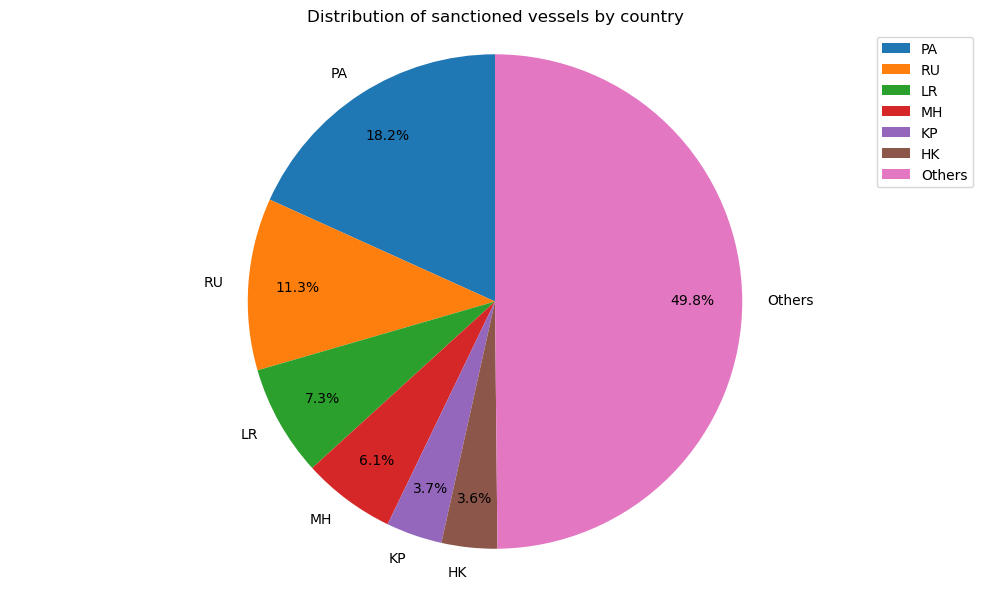

In [65]:
country_counts = df_maritime['countries'].value_counts()

country_percentage = country_counts / country_counts.sum()

main_countries = country_counts[country_percentage >= 0.02]
other_countries = country_counts[country_percentage < 0.02].sum()

plot_data = main_countries.copy()
if other_countries > 0:
    plot_data['Others'] = other_countries

fig = plt.figure(figsize=(10, 6))
plot_data.plot(
    kind='pie',
    autopct='%1.1f%%', # autopct to show percentage on the pie chart
    startangle=90,
    pctdistance=0.8
)

plt.title('Distribution of sanctioned vessels by country')
plt.axis('equal')
plt.tight_layout()
plt.legend()
plt.show()

##### Sanctioned securities

In [66]:
df_securities

,caption,lei,perm_id,isins,ric,countries,sanctioned,eo_14071,public,id,url,datasets,risk_datasets,aliases,referents
0,"Myanmar Yatai International Holding Group Co.,...",NaN,NaN,NaN,NaN,MM,t,f,f,NK-223CQDBzp8MRkdJMDiqXn3,https://www.opensanctions.org/entities/NK-223C...,us_ofac_sdn,us_ofac_sdn,"Myanmar Yatai International Holding Group Co.,...",oc-companies-mm-1fc-2016-2017-kyn;ofac-54742;o...
1,OJSC EHMZ named after N. D. Zelinsky,NaN,NaN,NaN,NaN,RU,t,f,f,NK-226GXBdQ5p6NjgrTpTQNVW,https://www.opensanctions.org/entities/NK-226G...,ch_seco_sanctions;eu_fsf;eu_journal_sanctions,ch_seco_sanctions;eu_fsf;eu_journal_sanctions,Fábrica de produtos químicos e mecânicos que r...,be-fod-e74ddc4806de2878afe5caf44883341bc23dad3...
2,Limited Liability Company Specialized Develope...,NaN,NaN,NaN,NaN,RU,t,f,f,NK-22MHXvQQufBgTjUWgUbWb8,https://www.opensanctions.org/entities/NK-22MH...,us_ofac_sdn,us_ofac_sdn,LLC Specialized Developer Alabuga South Park;L...,ofac-47297;ofac-pr-8b6d0f8d6541274066986792288...
3,Digital Marketing Awards FZ LLC,NaN,5090601059,NaN,NaN,AE,t,f,f,NK-22T6dTsc6umYgEA33vME3t,https://www.opensanctions.org/entities/NK-22T6...,permid;us_ofac_sdn,us_ofac_sdn,Digital Marketing Awards FZ LLC;Digital Market...,ofac-49834;ofac-pr-14fa36d7ba9e9f60363ab2b7bab...
4,EKVIK LIMITED LIABILITY COMPANY,NaN,NaN,NaN,NaN,RU,t,f,f,NK-22cQD3a8GDRSuoW5mus3F3,https://www.opensanctions.org/entities/NK-22cQ...,us_ofac_sdn,us_ofac_sdn,EKVIK LIMITED LIABILITY COMPANY,ofac-51081;ofac-pr-c7983e4cf948daa5d07f11f8cfd...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11888,Jiangyin Lianyun Co. Ltd.,NaN,NaN,NaN,NaN,CN,t,f,f,us-uflpa-e038fe2617a53578a9a891aa32dab5fd1baa7608,https://www.opensanctions.org/entities/us-uflp...,us_dhs_uflpa,us_dhs_uflpa,Jiangyin Intermodal Transport Co. and Jiangyin...,NaN
11889,Jiangsu Yinhai Nongjiale Storage Co. Ltd.,NaN,NaN,NaN,NaN,CN,t,f,f,us-uflpa-e650617987b2f3ac5deb8d0fcf04e18b89dde537,https://www.opensanctions.org/entities/us-uflp...,us_dhs_uflpa,us_dhs_uflpa,Jiangsu Yinhai Nongjiale Storage Co. Ltd.,NaN
11890,Tianjin Dunhe International Trade Co. Ltd.,NaN,NaN,NaN,NaN,CN,t,f,f,us-uflpa-ec1fcb7ba4b0c3da7cc8492739eaedb470ff5e2f,https://www.opensanctions.org/entities/us-uflp...,us_dhs_uflpa,us_dhs_uflpa,Dunhe Foods;Tianjin Dunhe International Trade ...,NaN
11891,Qingdao Vital Nutraceutical Ingredients BioSci...,NaN,NaN,NaN,NaN,CN,t,f,f,us-uflpa-ed1fd084a8c6cf5d576d01c1d37e6c2ba48f2978,https://www.opensanctions.org/entities/us-uflp...,us_dhs_uflpa,us_dhs_uflpa,Qingdao Vital Nutraceutical Ingredients BioSci...,NaN


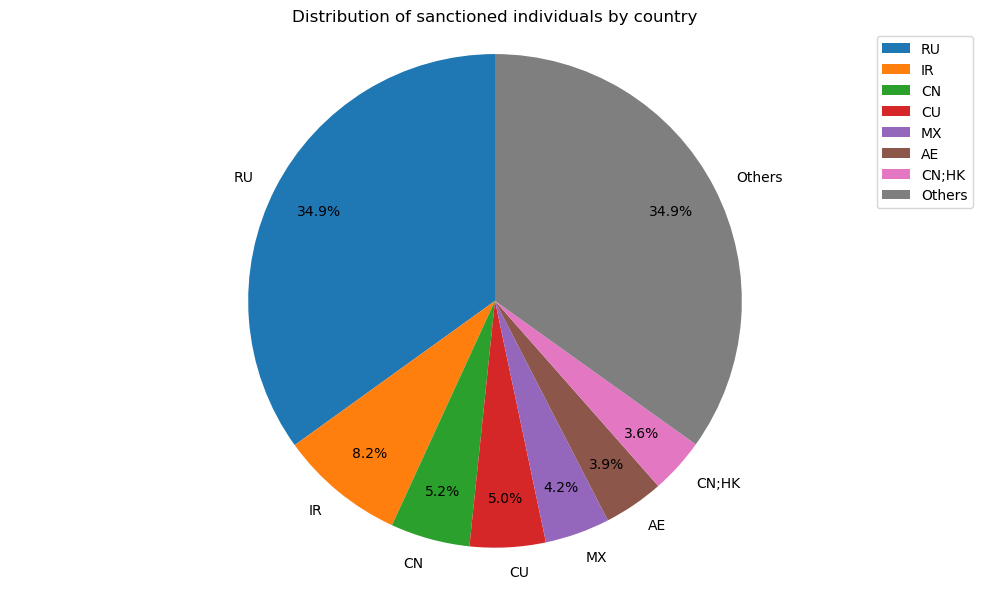

In [67]:
country_counts = df_securities['countries'].value_counts()

country_percentage = country_counts / country_counts.sum()

main_countries = country_counts[country_percentage >= 0.02]
other_countries = country_counts[country_percentage < 0.02].sum()

plot_data = main_countries.copy()
if other_countries > 0:
    plot_data['Others'] = other_countries

fig = plt.figure(figsize=(10, 6))
plot_data.plot(
    kind='pie',
    autopct='%1.1f%%', # autopct to show percentage on the pie chart
    startangle=90,
    pctdistance=0.8
)

plt.title('Distribution of sanctioned individuals by country')
plt.axis('equal')
plt.tight_layout()
plt.legend()
plt.show()

## Part II: Data Analysis and Modeling
---

### RQ1: Are there any potential links between the sanctioned individuals and other entities in the consolidated sanctions dataset, such as organisations or vessels, that could indicate potential patterns of sanctions evasion or risk?

### RQ1: Are there any significant overlaps between the entities in the consolidated sanctions dataset and the PEPs dataset, and what does this reveal about the relationship between sanctioned entities and politically exposed persons?

### RQ2: Are these entities more likely to be involved in certain types of activities - namely maritime activities - and if so, what are the implications for sanctions enforcement and compliance efforts in the maritime industry?

Now we further extend our analysis by associating the entities in the merged dataset with the maritime dataset. This will allow us to explore any potential connections between the entities in the consolidated sanctions and PEPs datasets and maritime activities, such as flag states or countries of operation. We can perform a similar merge operation based on common attributes, such as country names or other relevant identifiers, to create a comprehensive view of the data across these different domains.

The vessels in the `df_maritime` dataset are not standalone entities - they are extensions of sanctioned actors. A vessel owned or operated by a sanctioned entity can be itself a sanction circumvention instrument, as it can be used to facilitate illicit activities such as smuggling or conducting unauthorized trade. By linking the maritime dataset with the consolidated sanctions and PEPs datasets, we can identify potential maritime connections to sanctioned entities and PEPs, which may reveal patterns of sanctions evasion or illicit activities.

To do so, we can implement a system that matches on shared identifiers or name overlap between maritime entities and the consolidated sanctions PEP base. First we establish a system of "conduit jurisdictions" - countries that are commonly used as flags of convenience for vessels owned or operated by sanctioned entities. We can then use fuzzy matching techniques to identify potential matches between vessel names, and the names of the sanctioned entities and PEPs in the main dataset. This can help us uncover hidden connections and potential risks associated with maritime activities linked to sanctioned entities and PEPs.

And then Look for vessels where:

- The operator or owner name fuzzy-matches a sanctioned entity in your base
- The flag state is a known conduit jurisdiction (Panama, Marshall Islands, Belize, Comoros — the dark fleet registers)

In [ ]:
conduit_jurisdictions = ['PA', 'VU', 'MT', 'KM']

known_conduits_vessels = [
("RU", "RU"),  # Russia
("RU", "PA"),  # Panama
("RU", "BB"),  # Barbados
("RU", "GA"),  # Gabon
("RU", "TZ"),  # Tanzania
("RU", "CK"),  # Cook Islands
("IR", "IR"),  # Iran
("IR", "PA"),  # Panama
("IR", "BB"),  # Barbados
("IR", "CK"),  # Cook Islands
("IR", "TZ")   # Tanzania
]

## Part III: Machine Learning and Predictive Modeling
---